In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

# Project paths
PROJECT_DIR = Path.cwd()

SEARCH_DIRS = [
    PROJECT_DIR / "data" / "processed",
    PROJECT_DIR / "output" / "tables",
    PROJECT_DIR / "data",
    PROJECT_DIR,
]

# Identify the processed NUMBAT dataset
candidates = []

for folder in SEARCH_DIRS:
    if folder.exists():
        candidates.extend(folder.glob("*.csv"))

candidates = list(dict.fromkeys(candidates))

required_columns = {"Year", "Day_Type", "ASC", "Station"}

matching_files = []

for file in candidates:
    try:
        columns = set(pd.read_csv(file, nrows=0).columns)
        if required_columns.issubset(columns):
            matching_files.append(file)
    except Exception:
        continue

print("Potential NUMBAT datasets:")

for file in matching_files:
    print(file)

if len(matching_files) != 1:
    raise ValueError(
        f"Expected exactly one matching dataset, found {len(matching_files)}. "
        "Please set DATA_FILE manually."
    )

DATA_FILE = matching_files[0]

df = pd.read_csv(DATA_FILE)

print("\nLoaded:", DATA_FILE)
print("Dataset shape:", df.shape)
print(df.head())

Potential NUMBAT datasets:
/Users/ovo/Desktop/Grad/Internship/Data_for_Humanity_Internship/do-starter-playground/Model/data/processed/numbat_station_profiles.csv

Loaded: /Users/ovo/Desktop/Grad/Internship/Data_for_Humanity_Internship/do-starter-playground/Model/data/processed/numbat_station_profiles.csv
Dataset shape: (3220, 101)
   Year Day_Type   ASC       Station  0500-0515  0515-0530  0530-0545  \
0  2019   Friday  ACTu    Acton Town    16.7320    32.2792    53.0082   
1  2019   Friday  ALDu       Aldgate     7.0292    11.8854    27.8046   
2  2019   Friday  ALEu  Aldgate East    12.5400    25.8030    41.7298   
3  2019   Friday  ALPu      Alperton    16.7546    35.0548    52.4168   
4  2019   Friday  AMEu      Amersham    16.8454    16.9278    32.2344   

   0545-0600  0600-0615  0615-0630  ...  0245-0300  0300-0315  0315-0330  \
0    81.8154   110.7444   147.5696  ...     30.069    26.4088    29.1808   
1    39.2266    68.8404   102.2734  ...      0.000     0.0000     0.0000   


In [2]:
# Identify the 96 quarter-hour columns
qhr_cols = [
    col for col in df.columns
    if re.fullmatch(r"\d{4}-\d{4}", str(col))
]

print("Number of QHR columns:", len(qhr_cols))
print("Years:", sorted(df["Year"].unique()))
print("Day types:", sorted(df["Day_Type"].unique()))

assert len(qhr_cols) == 96, "Expected 96 quarter-hour columns."

assert set(df["Year"].unique()) == {2019, 2022, 2025}

assert set(df["Day_Type"].unique()) == {
    "Mon-Thu", "Friday", "Saturday", "Sunday"
}

# Check duplicate station-day records
duplicates = df.duplicated(
    subset=["Year", "Day_Type", "ASC"]
)

print("Duplicate records:", duplicates.sum())

# Check missing values
print(
    "Missing QHR values:",
    df[qhr_cols].isna().sum().sum()
)

# Check unique station counts
print("\nStations per year and day type:")
print(
    df.groupby(["Year", "Day_Type"])["ASC"]
      .nunique()
      .unstack()
)

if duplicates.any():
    raise ValueError("Duplicate station-day records found.")

if df[qhr_cols].isna().any().any():
    raise ValueError("Missing QHR values found.")

Number of QHR columns: 96
Years: [np.int64(2019), np.int64(2022), np.int64(2025)]
Day types: ['Friday', 'Mon-Thu', 'Saturday', 'Sunday']
Duplicate records: 0
Missing QHR values: 0

Stations per year and day type:
Day_Type  Friday  Mon-Thu  Saturday  Sunday
Year                                       
2019         267      267       267     267
2022         269      269       269     269
2025         269      269       269     269


In [3]:
# Find stations available in all three years
stations_by_year = {
    year: set(
        df.loc[df["Year"] == year, "ASC"].unique()
    )
    for year in [2019, 2022, 2025]
}

common_stations = sorted(
    set.intersection(*stations_by_year.values())
)

print("Common stations across all years:", len(common_stations))

# Keep stations available across all three years
common_df = df[
    df["ASC"].isin(common_stations)
].copy()

# Exclude stations with zero daily flow in any year/day type
daily_totals = (
    common_df.groupby(["ASC", "Year", "Day_Type"])[qhr_cols]
    .sum()
    .sum(axis=1)
)

invalid_stations = daily_totals[
    daily_totals <= 0
].index.get_level_values("ASC").unique().tolist()

print("Stations excluded due to zero daily flow:", invalid_stations)

common_df = common_df[
    ~common_df["ASC"].isin(invalid_stations)
].copy()

common_stations = sorted(common_df["ASC"].unique())

print("Final common stations:", len(common_stations))


Common stations across all years: 267
Stations excluded due to zero daily flow: ['SHLu']
Final common stations: 266


In [4]:

# # Diagnose zero or negative daily flow
# diagnostic = common_df.copy()

# diagnostic["Daily_Total"] = diagnostic[qhr_cols].sum(axis=1)

# problem_rows = diagnostic[
#     diagnostic["Daily_Total"] <= 0
# ]

# print("Rows with zero or negative daily flow:")
# print(
#     problem_rows[
#         ["Year", "Day_Type", "ASC", "Station", "Daily_Total"]
#     ].to_string(index=False)
# )

# print("\nNumber of problematic rows:", len(problem_rows))

# print("\nNegative values:")
# print((diagnostic[qhr_cols] < 0).sum().sum())

# print("\nZero-total rows by year and day type:")
# print(
#     problem_rows.groupby(["Year", "Day_Type"])
#     .size()
# )

In [5]:

day_types = ["Mon-Thu", "Friday", "Saturday", "Sunday"]

# Normalize each station's profile within each day type
normalized_df = common_df.copy()

for day_type in day_types:

    mask = normalized_df["Day_Type"] == day_type

    row_totals = normalized_df.loc[mask, qhr_cols].sum(axis=1)

    if (row_totals <= 0).any():
        raise ValueError(
            f"Zero or negative daily flow found in {day_type}."
        )

    normalized_df.loc[mask, qhr_cols] = (
        normalized_df.loc[mask, qhr_cols]
        .div(row_totals, axis=0)
    )

print("Normalized data shape:", normalized_df.shape)
print(normalized_df.head())

Normalized data shape: (3192, 101)
   Year Day_Type   ASC       Station  0500-0515  0515-0530  0530-0545  \
0  2019   Friday  ACTu    Acton Town   0.000804   0.001550   0.002546   
1  2019   Friday  ALDu       Aldgate   0.000217   0.000368   0.000860   
2  2019   Friday  ALEu  Aldgate East   0.000259   0.000533   0.000861   
3  2019   Friday  ALPu      Alperton   0.001726   0.003611   0.005400   
4  2019   Friday  AMEu      Amersham   0.002245   0.002256   0.004296   

   0545-0600  0600-0615  0615-0630  ...  0245-0300  0300-0315  0315-0330  \
0   0.003930   0.005319   0.007088  ...   0.001444   0.001268   0.001402   
1   0.001213   0.002129   0.003163  ...   0.000000   0.000000   0.000000   
2   0.001249   0.001719   0.002252  ...   0.000000   0.000000   0.000000   
3   0.008232   0.010649   0.014000  ...   0.000000   0.000000   0.000000   
4   0.006698   0.008908   0.010685  ...   0.000000   0.000000   0.000000   

   0330-0345  0345-0400  0400-0415  0415-0430  0430-0445  0445-0500  

In [6]:
def build_station_matrix(data, year):

    year_data = data[data["Year"] == year]

    profile_parts = []

    for day_type in day_types:

        subset = (
            year_data[year_data["Day_Type"] == day_type]
            .set_index("ASC")
            .sort_index()
        )

        subset = subset.loc[common_stations, qhr_cols]

        subset.columns = [
            f"{day_type}_{col}"
            for col in qhr_cols
        ]

        profile_parts.append(subset)

    matrix = pd.concat(profile_parts, axis=1)

    return matrix


X_2019 = build_station_matrix(normalized_df, 2019)
X_2022 = build_station_matrix(normalized_df, 2022)
X_2025 = build_station_matrix(normalized_df, 2025)

print("2019 matrix:", X_2019.shape)
print("2022 matrix:", X_2022.shape)
print("2025 matrix:", X_2025.shape)

assert X_2019.shape[1] == 384
assert X_2022.shape[1] == 384
assert X_2025.shape[1] == 384

2019 matrix: (266, 384)
2022 matrix: (266, 384)
2025 matrix: (266, 384)


K = 2: Silhouette Score = 0.2736
K = 3: Silhouette Score = 0.1694
K = 4: Silhouette Score = 0.1738
K = 5: Silhouette Score = 0.1581
K = 6: Silhouette Score = 0.1547
K = 7: Silhouette Score = 0.1424
K = 8: Silhouette Score = 0.1643


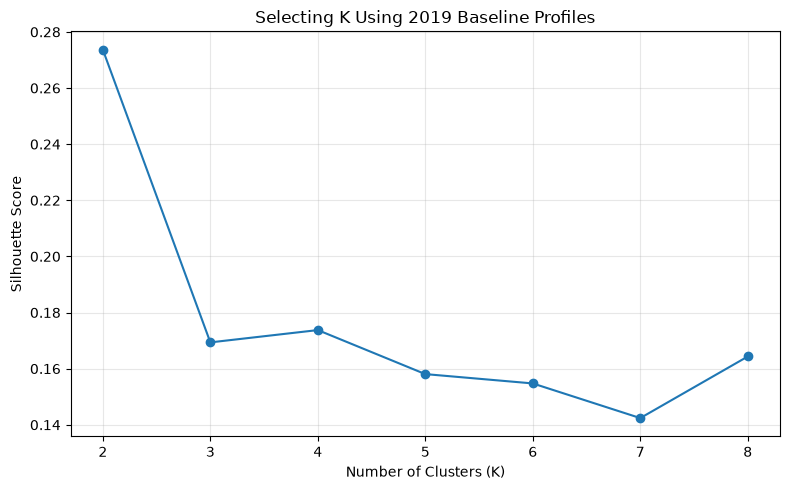

Selected K: 2
Clustering complete.
    ASC  Year  Cluster
0  ACTu  2019        0
1  AGRu  2019        0
2  ALDu  2019        1
3  ALEu  2019        1
4  ALPu  2019        0
5  AMEu  2019        0
6  ANGu  2019        1
7  ARCu  2019        1
8  ARLu  2019        1
9  BALu  2019        0

Cluster distribution by year:
Cluster    0    1
Year             
2019     150  116
2022     118  148
2025     113  153


In [7]:

# ==========================================
# Select K using 2019 baseline profiles
# ==========================================

k_values = range(2, 9)
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_2019)

    score = silhouette_score(X_2019, labels)

    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")


# Plot silhouette scores
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Selecting K Using 2019 Baseline Profiles")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Select the best K
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Selected K:", best_k)


# ==========================================
# Fit final model on 2019 baseline
# ==========================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

kmeans.fit(X_2019)


# ==========================================
# Predict cluster membership across years
# ==========================================

cluster_results = []

for year, matrix in [
    (2019, X_2019),
    (2022, X_2022),
    (2025, X_2025)
]:

    labels = kmeans.predict(matrix)

    year_result = pd.DataFrame({
        "ASC": matrix.index,
        "Year": year,
        "Cluster": labels
    })

    cluster_results.append(year_result)


cluster_df = pd.concat(
    cluster_results,
    ignore_index=True
)

print("Clustering complete.")
print(cluster_df.head(10))


# ==========================================
# Cluster distribution by year
# ==========================================

print("\nCluster distribution by year:")

print(
    cluster_df.groupby(["Year", "Cluster"])
    .size()
    .unstack(fill_value=0)
)



In [8]:
# ==========================================
# Export station-level cluster assignments
# ==========================================

OUTPUT_DIR = PROJECT_DIR / "output" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cluster_df.to_csv(
    OUTPUT_DIR / "part2_cluster_assignments.csv",
    index=False
)

cluster_pivot = cluster_df.pivot(
    index="ASC",
    columns="Year",
    values="Cluster"
)

transition_output = (
    pd.crosstab(
        cluster_pivot[2019],
        cluster_pivot[2025],
        rownames=["2019_Cluster"],
        colnames=["2025_Cluster"]
    )
)

transition_output.to_csv(
    OUTPUT_DIR / "part2_cluster_transitions.csv"
)

In [9]:
# ==========================================
# Cluster Distance and Boundary Analysis
# ==========================================

from sklearn.metrics import pairwise_distances

distance_records = []

year_matrices = {
    2019: X_2019,
    2022: X_2022,
    2025: X_2025
}

for year, matrix in year_matrices.items():

    # Distance from each station to both 2019-trained centroids
    distances = pairwise_distances(
        matrix,
        kmeans.cluster_centers_,
        metric="euclidean"
    )

    year_labels = (
        cluster_df[cluster_df["Year"] == year]
        .set_index("ASC")["Cluster"]
    )

    for i, asc in enumerate(matrix.index):

        d0 = distances[i, 0]
        d1 = distances[i, 1]

        distance_records.append({
            "ASC": asc,
            "Year": year,
            "Assigned_Cluster": year_labels.loc[asc],
            "Distance_0": d0,
            "Distance_1": d1,
            "Distance_Gap": abs(d0 - d1),
            "Relative_Distance_Gap": (
                abs(d0 - d1) / max(d0, d1)
                if max(d0, d1) > 0 else 0
            )
        })


cluster_distances = pd.DataFrame(distance_records)

# Compare 2019 and 2025 assignments
distance_pivot = cluster_distances.pivot(
    index="ASC",
    columns="Year",
    values="Assigned_Cluster"
)

changed_stations = (
    distance_pivot[
        distance_pivot[2019] != distance_pivot[2025]
    ].index
)

cluster_distances["Transition_Status"] = "Stable"

cluster_distances.loc[
    cluster_distances["ASC"].isin(changed_stations),
    "Transition_Status"
] = "Changed Cluster"

# Identify low-margin cases among 2025 switchers
switcher_2025 = cluster_distances[
    (cluster_distances["Year"] == 2025) &
    (cluster_distances["ASC"].isin(changed_stations))
]

boundary_cutoff = switcher_2025[
    "Relative_Distance_Gap"
].quantile(0.25)

cluster_distances["Boundary_Status"] = "Not a switcher"

cluster_distances.loc[
    cluster_distances["ASC"].isin(changed_stations),
    "Boundary_Status"
] = "Larger distance margin"

cluster_distances.loc[
    (cluster_distances["Year"] == 2025) &
    (cluster_distances["ASC"].isin(changed_stations)) &
    (cluster_distances["Relative_Distance_Gap"] <= boundary_cutoff),
    "Boundary_Status"
] = "Near-boundary switcher"

distance_output = (
    OUTPUT_DIR / "part2_cluster_distances.csv"
)

cluster_distances.to_csv(
    distance_output,
    index=False
)

print("Number of stations changing cluster:", len(changed_stations))
print("2025 switcher boundary cutoff:", boundary_cutoff)

print("\n2025 switcher distance details:")
print(
    switcher_2025.sort_values(
        "Relative_Distance_Gap"
    ).round(4).to_string(index=False)
)

print("\nSaved to:", distance_output)

Number of stations changing cluster: 37
2025 switcher boundary cutoff: 0.07279052108881004

2025 switcher distance details:
 ASC  Year  Assigned_Cluster  Distance_0  Distance_1  Distance_Gap  Relative_Distance_Gap Transition_Status
CNTu  2025                 1      0.0476      0.0475        0.0001                 0.0016   Changed Cluster
STKu  2025                 1      0.0462      0.0456        0.0006                 0.0123   Changed Cluster
TBYu  2025                 1      0.0353      0.0342        0.0011                 0.0318   Changed Cluster
WACu  2025                 1      0.0508      0.0490        0.0019                 0.0365   Changed Cluster
BWRu  2025                 1      0.0416      0.0395        0.0021                 0.0493   Changed Cluster
TPLu  2025                 1      0.0423      0.0401        0.0021                 0.0505   Changed Cluster
CFSu  2025                 1      0.0446      0.0422        0.0024                 0.0528   Changed Cluster
SWFu  2025  

In [10]:
# ==========================================
# Track station-level cluster transitions
# ==========================================

cluster_pivot = cluster_df.pivot(
    index="ASC",
    columns="Year",
    values="Cluster"
)

print("2019 to 2025 cluster transitions:")
print(
    pd.crosstab(
        cluster_pivot[2019],
        cluster_pivot[2025],
        rownames=["2019 Cluster"],
        colnames=["2025 Cluster"]
    )
)

print("\nNumber of stations changing cluster:")
print(
    (cluster_pivot[2019] != cluster_pivot[2025]).sum()
)

print("\nTransition percentage:")
print(
    (cluster_pivot[2019] != cluster_pivot[2025]).mean() * 100
)

2019 to 2025 cluster transitions:
2025 Cluster    0    1
2019 Cluster          
0             113   37
1               0  116

Number of stations changing cluster:
37

Transition percentage:
13.909774436090224


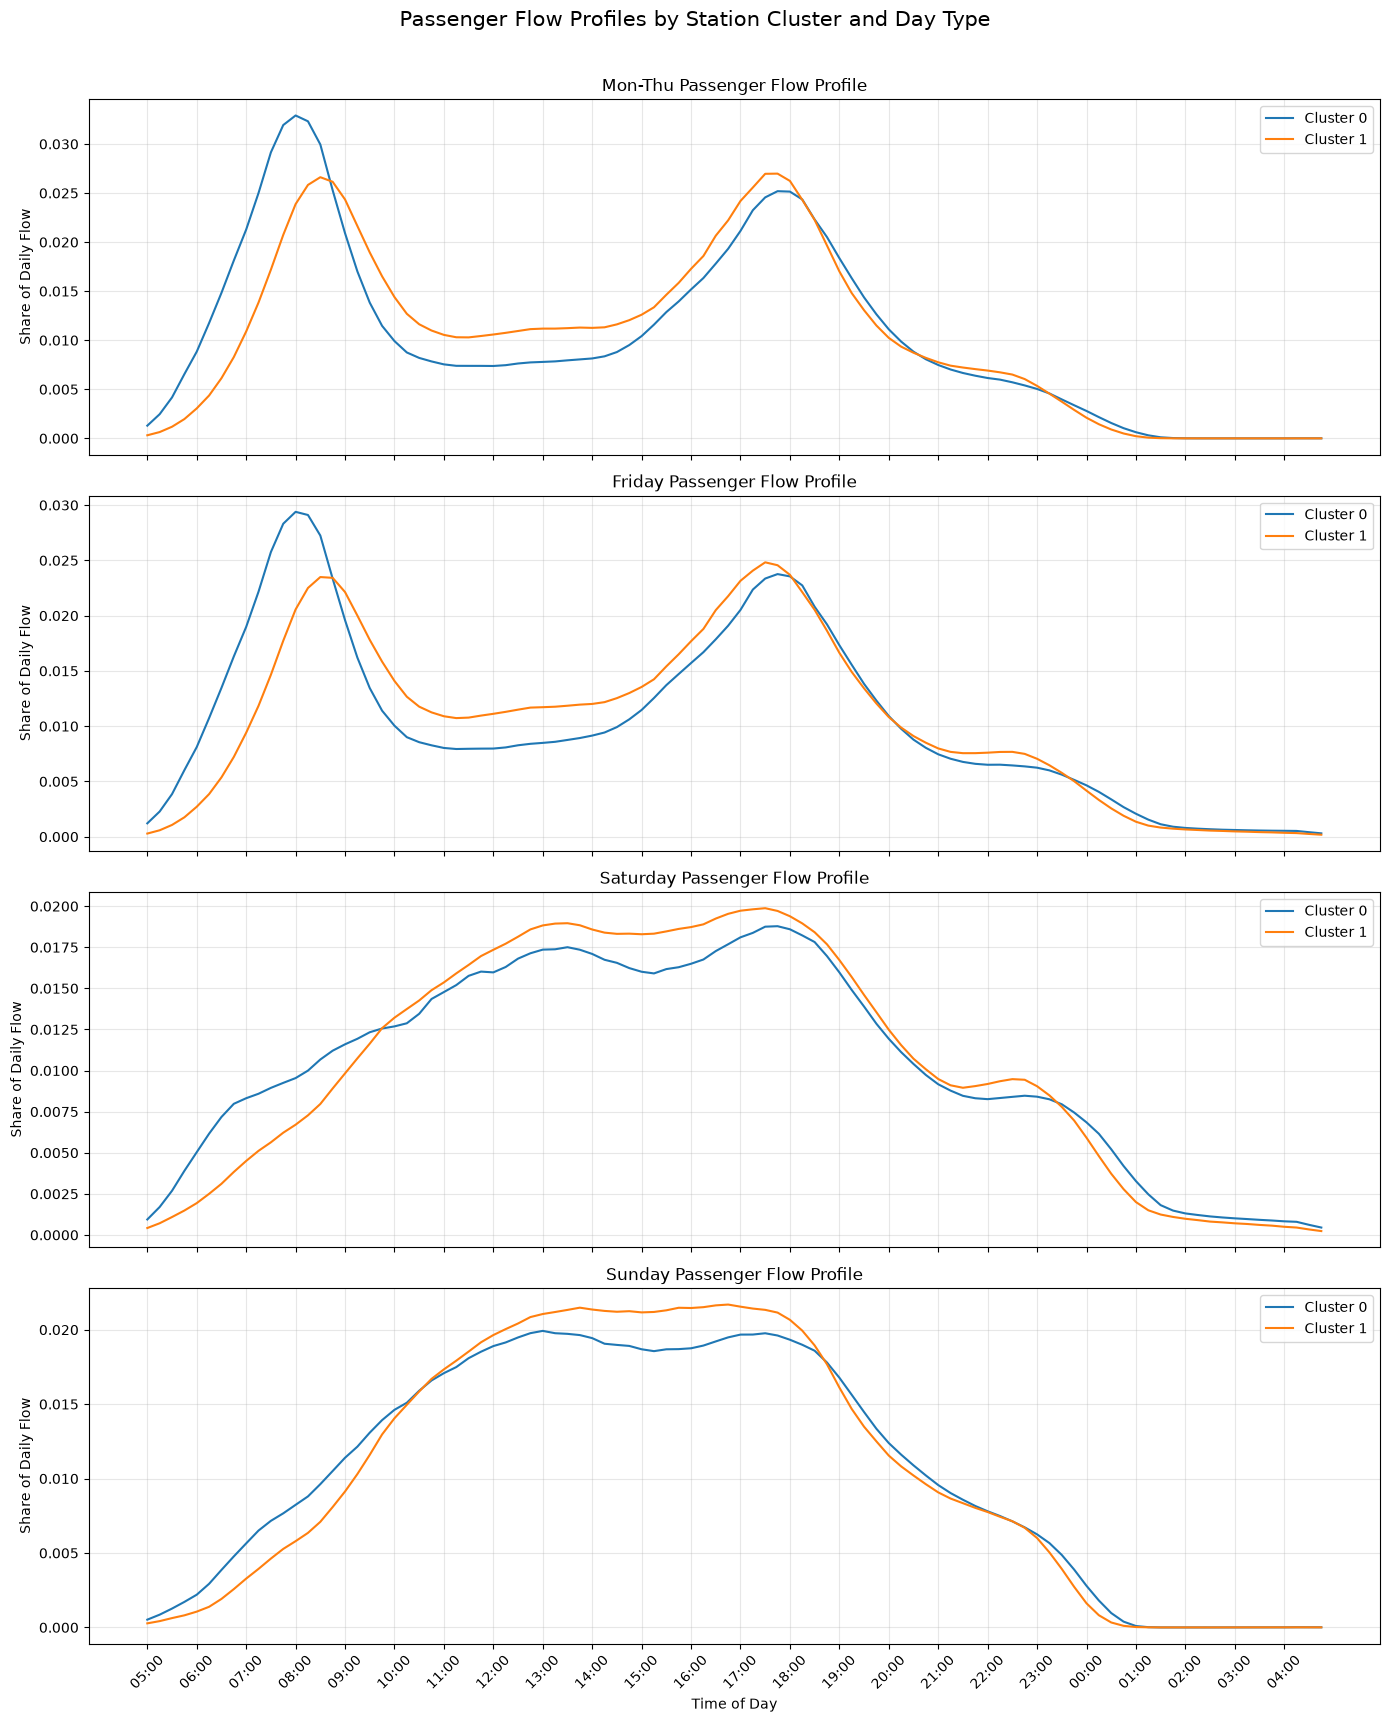

In [11]:
# ==========================================
# Plot average daily profiles by cluster
# ==========================================

# Explicitly include all four day types
day_types = ["Mon-Thu", "Friday", "Saturday", "Sunday"]

# Attach cluster labels to 2025 normalized profiles
cluster_2025 = (
    cluster_df[cluster_df["Year"] == 2025]
    .set_index("ASC")
)

plot_data = normalized_df[
    normalized_df["Year"] == 2019
].copy()

cluster_2019 = (
    cluster_df[cluster_df["Year"] == 2019]
    .set_index("ASC")
)

plot_data["Cluster"] = (
    plot_data["ASC"].map(cluster_2019["Cluster"])
)


# Create four subplots, one for each day type
fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 17),
    sharex=True
)

for ax, day_type in zip(axes, day_types):

    day_data = plot_data[
        plot_data["Day_Type"] == day_type
    ]

    for cluster in sorted(day_data["Cluster"].dropna().unique()):

        cluster_profile = (
            day_data[day_data["Cluster"] == cluster][qhr_cols]
            .mean(axis=0)
        )

        ax.plot(
            range(96),
            cluster_profile.values,
            label=f"Cluster {int(cluster)}"
        )

    ax.set_title(f"{day_type} Passenger Flow Profile")
    ax.set_ylabel("Share of Daily Flow")
    ax.legend()
    ax.grid(alpha=0.3)

# Hourly time labels
hour_positions = list(range(0, 96, 4))

hour_labels = [
    qhr_cols[i][:2] + ":00"
    for i in hour_positions
]

axes[-1].set_xticks(hour_positions)
axes[-1].set_xticklabels(hour_labels, rotation=45)
axes[-1].set_xlabel("Time of Day")

plt.suptitle(
    "Passenger Flow Profiles by Station Cluster and Day Type",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

In [12]:
print("Day types in normalized_df:")
print(normalized_df["Day_Type"].value_counts())

print("\n2025 Sunday records:")
print(
    normalized_df[
        (normalized_df["Year"] == 2025) &
        (normalized_df["Day_Type"] == "Sunday")
    ].shape
)

Day types in normalized_df:
Day_Type
Friday      798
Mon-Thu     798
Saturday    798
Sunday      798
Name: count, dtype: int64

2025 Sunday records:
(266, 101)


In [13]:
# Create output directories
OUTPUT_DIR = PROJECT_DIR / "output" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Export station-level cluster assignments
cluster_output = OUTPUT_DIR / "station_clusters.csv"

cluster_df.to_csv(
    cluster_output,
    index=False
)


# Export average profiles for each cluster and day type
profile_records = []

for day_type in day_types:

    day_data = plot_data[
        plot_data["Day_Type"] == day_type
    ]

    for cluster in sorted(day_data["Cluster"].unique()):

        mean_profile = (
            day_data[day_data["Cluster"] == cluster][qhr_cols]
            .mean(axis=0)
        )

        for time_bin, value in mean_profile.items():

            profile_records.append({
                "Day_Type": day_type,
                "Cluster": cluster,
                "Time": time_bin,
                "Flow_Share": value
            })


cluster_profiles = pd.DataFrame(profile_records)

profile_output = OUTPUT_DIR / "cluster_average_profiles.csv"

cluster_profiles.to_csv(
    profile_output,
    index=False
)


print("========================================")
print("PART 02 CLUSTERING COMPLETE")
print("========================================")

print("Selected K:", best_k)
print("Common stations:", len(common_stations))
print("Station cluster output:", cluster_output)
print("Average profile output:", profile_output)

PART 02 CLUSTERING COMPLETE
Selected K: 2
Common stations: 266
Station cluster output: /Users/ovo/Desktop/Grad/Internship/Data_for_Humanity_Internship/do-starter-playground/Model/output/tables/station_clusters.csv
Average profile output: /Users/ovo/Desktop/Grad/Internship/Data_for_Humanity_Internship/do-starter-playground/Model/output/tables/cluster_average_profiles.csv


In [14]:
# ==========================================
# Cell 8: Prepare Recovery Dataset
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np

# Locate Part 01 processed dataset
PROJECT_DIR = Path.cwd()

DATA_FILE = PROJECT_DIR / "data" / "processed" / "london_underground_clean.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE}. Please check the file path."
    )

annual_df = pd.read_csv(DATA_FILE)

print("Annual dataset shape:", annual_df.shape)
print("Columns:", annual_df.columns.tolist())


# Keep London Underground only
annual_df = annual_df[
    annual_df["Mode"].astype(str).str.upper().str.strip() == "LU"
].copy()

# Standardise station codes
annual_df["MASC"] = annual_df["MASC"].astype(str).str.strip()

# Use 2019 cluster assignment as the fixed station classification
cluster_mapping = (
    cluster_df[cluster_df["Year"] == 2019][["ASC", "Cluster"]]
    .drop_duplicates()
    .copy()
)

cluster_mapping["ASC"] = (
    cluster_mapping["ASC"].astype(str).str.strip()
)

# Merge cluster labels with Annual Counts
recovery_df = annual_df.merge(
    cluster_mapping,
    left_on="MASC",
    right_on="ASC",
    how="inner",
    validate="many_to_one"
)

print("\nMerged dataset shape:", recovery_df.shape)
print("Matched stations:", recovery_df["MASC"].nunique())

print("\nStations by year:")
print(recovery_df.groupby("Year")["MASC"].nunique())

# Check unmatched station codes
unmatched = sorted(
    set(annual_df["MASC"].unique())
    - set(cluster_mapping["ASC"].unique())
)

print("\nUnmatched LU station codes:", unmatched)

assert recovery_df["MASC"].nunique() == 266, (
    "Expected 266 matched stations. Check the station-code mapping."
)

Annual dataset shape: (807, 16)
Columns: ['Year', 'Mode', 'MNLC', 'MASC', 'Station', 'Coverage', 'Source', 'MTT_Entry', 'Friday_Entry', 'Saturday_Entry', 'Sunday_Entry', 'MTT_Exit', 'Friday_Exit', 'Saturday_Exit', 'Sunday_Exit', 'Annualised_EnEx']

Merged dataset shape: (798, 18)
Matched stations: 266

Stations by year:
Year
2019    266
2022    266
2025    266
Name: MASC, dtype: int64

Unmatched LU station codes: ['BPSu', 'NIEu', 'SHLu']


In [15]:
# ==========================================
# Cell 9: Calculate Cluster-Level Recovery
# ==========================================

# Define passenger flow columns
flow_columns = {
    "Mon-Thu": ("MTT_Entry", "MTT_Exit"),
    "Friday": ("Friday_Entry", "Friday_Exit"),
    "Saturday": ("Saturday_Entry", "Saturday_Exit"),
    "Sunday": ("Sunday_Entry", "Sunday_Exit")
}

# Calculate total passenger flow for each day type
for day_type, (entry_col, exit_col) in flow_columns.items():

    recovery_df[entry_col] = pd.to_numeric(
        recovery_df[entry_col], errors="coerce"
    )

    recovery_df[exit_col] = pd.to_numeric(
        recovery_df[exit_col], errors="coerce"
    )

    recovery_df[f"{day_type}_Flow"] = (
        recovery_df[entry_col] + recovery_df[exit_col]
    )


# Reshape into a long-format dataset
flow_records = []

for day_type in flow_columns:

    temp = recovery_df[
        ["Year", "MASC", "Station", "Cluster", f"{day_type}_Flow"]
    ].copy()

    temp = temp.rename(
        columns={f"{day_type}_Flow": "Passenger_Flow"}
    )

    temp["Day_Type"] = day_type

    flow_records.append(temp)


flow_df = pd.concat(flow_records, ignore_index=True)

# Aggregate passenger flow by year, cluster and day type
cluster_recovery = (
    flow_df.groupby(["Year", "Cluster", "Day_Type"])
    ["Passenger_Flow"]
    .sum()
    .reset_index()
)

# Calculate 2019 baseline for each cluster and day type
baseline = (
    cluster_recovery[cluster_recovery["Year"] == 2019]
    [["Cluster", "Day_Type", "Passenger_Flow"]]
    .rename(columns={"Passenger_Flow": "Baseline_2019"})
)

cluster_recovery = cluster_recovery.merge(
    baseline,
    on=["Cluster", "Day_Type"],
    how="left",
    validate="many_to_one"
)

cluster_recovery["Recovery_Index"] = (
    cluster_recovery["Passenger_Flow"]
    / cluster_recovery["Baseline_2019"]
    * 100
)

cluster_recovery = cluster_recovery.sort_values(
    ["Day_Type", "Cluster", "Year"]
).reset_index(drop=True)

print(cluster_recovery.round(2).to_string(index=False))

 Year  Cluster Day_Type  Passenger_Flow  Baseline_2019  Recovery_Index
 2019        0   Friday      2922244.00      2922244.0          100.00
 2022        0   Friday      2171250.88      2922244.0           74.30
 2025        0   Friday      2249446.26      2922244.0           76.98
 2019        1   Friday      6680807.00      6680807.0          100.00
 2022        1   Friday      4720016.09      6680807.0           70.65
 2025        1   Friday      4969068.66      6680807.0           74.38
 2019        0  Mon-Thu      2892053.00      2892053.0          100.00
 2022        0  Mon-Thu      2239591.30      2892053.0           77.44
 2025        0  Mon-Thu      2367610.46      2892053.0           81.87
 2019        1  Mon-Thu      6458939.00      6458939.0          100.00
 2022        1  Mon-Thu      4867495.39      6458939.0           75.36
 2025        1  Mon-Thu      5348195.64      6458939.0           82.80
 2019        0 Saturday      2067822.00      2067822.0          100.00
 2022 

In [16]:
# ==========================================
# Audit missing station-level flow data
# ==========================================

audit_records = []

for cluster in sorted(flow_df["Cluster"].unique()):

    for day_type in flow_columns:

        subset = flow_df[
            (flow_df["Cluster"] == cluster) &
            (flow_df["Day_Type"] == day_type)
        ]

        station_year = subset.pivot_table(
            index="MASC",
            columns="Year",
            values="Passenger_Flow",
            aggfunc="first"
        )

        for year in [2019, 2022, 2025]:

            if year not in station_year.columns:
                missing_count = len(station_year)
                missing_stations = list(station_year.index)
            else:
                missing_mask = station_year[year].isna()
                missing_count = int(missing_mask.sum())
                missing_stations = (
                    station_year.index[missing_mask].tolist()
                )

            audit_records.append({
                "Cluster": cluster,
                "Day_Type": day_type,
                "Year": year,
                "Station_Count": len(station_year),
                "Missing_Count": missing_count,
                "Missing_Stations": ", ".join(missing_stations)
            })

missing_audit = pd.DataFrame(audit_records)

print(missing_audit.to_string(index=False))

missing_audit.to_csv(
    OUTPUT_DIR / "part2_missing_flow_audit.csv",
    index=False
)

 Cluster Day_Type  Year  Station_Count  Missing_Count Missing_Stations
       0  Mon-Thu  2019            150              0                 
       0  Mon-Thu  2022            150              0                 
       0  Mon-Thu  2025            150              0                 
       0   Friday  2019            150              0                 
       0   Friday  2022            150              0                 
       0   Friday  2025            150              0                 
       0 Saturday  2019            150              0                 
       0 Saturday  2022            150              0                 
       0 Saturday  2025            150              0                 
       0   Sunday  2019            150              0                 
       0   Sunday  2022            150              0                 
       0   Sunday  2025            150              0                 
       1  Mon-Thu  2019            116              0                 
      

In [17]:
# ==========================================
# Bootstrap Confidence Intervals
# ==========================================

N_BOOTSTRAP = 5000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

bootstrap_records = []

# Station-level paired passenger flows
station_flows = flow_df.pivot_table(
    index=["MASC", "Cluster", "Day_Type"],
    columns="Year",
    values="Passenger_Flow",
    aggfunc="first"
).reset_index()

for cluster in sorted(station_flows["Cluster"].unique()):

    for day_type in flow_columns:

        subset = station_flows[
            (station_flows["Cluster"] == cluster) &
            (station_flows["Day_Type"] == day_type)
        ].copy()

        for year in [2022, 2025]:

            # Keep stations with valid paired observations
            paired = subset[
                subset[[2019, year]].notna().all(axis=1)
            ]

            baseline_values = paired[2019].to_numpy()
            target_values = paired[year].to_numpy()

            n = len(paired)

            if n == 0:
                continue

            # Point estimate: ratio of aggregate passenger flows
            point_estimate = (
                target_values.sum()
                / baseline_values.sum()
                * 100
            )

            bootstrap_estimates = []

            for _ in range(N_BOOTSTRAP):

                sampled_indices = rng.integers(
                    0, n, size=n
                )

                sampled_baseline = baseline_values[sampled_indices]
                sampled_target = target_values[sampled_indices]

                denominator = sampled_baseline.sum()

                if denominator > 0:

                    estimate = (
                        sampled_target.sum()
                        / denominator
                        * 100
                    )

                    bootstrap_estimates.append(estimate)

            lower_ci, upper_ci = np.percentile(
                bootstrap_estimates,
                [2.5, 97.5]
            )

            bootstrap_records.append({
                "Cluster": cluster,
                "Day_Type": day_type,
                "Year": year,
                "Station_Count": n,
                "Recovery_Index": point_estimate,
                "CI_Lower": lower_ci,
                "CI_Upper": upper_ci
            })


bootstrap_df = pd.DataFrame(bootstrap_records)

bootstrap_output = (
    OUTPUT_DIR / "part2_cluster_recovery_bootstrap.csv"
)

bootstrap_df.to_csv(
    bootstrap_output,
    index=False
)

print("Bootstrap results:")
print(bootstrap_df.round(2).to_string(index=False))

print("\nSaved to:", bootstrap_output)

Bootstrap results:
 Cluster Day_Type  Year  Station_Count  Recovery_Index  CI_Lower  CI_Upper
       0  Mon-Thu  2022            150           77.44     74.70     80.26
       0  Mon-Thu  2025            150           81.87     78.00     85.62
       0   Friday  2022            150           74.30     72.48     76.07
       0   Friday  2025            150           76.98     74.39     79.75
       0 Saturday  2022            150           90.81     88.14     93.39
       0 Saturday  2025            150           94.13     90.50     97.75
       0   Sunday  2022            150           87.28     84.75     89.91
       0   Sunday  2025            150           93.40     89.11     97.85
       1  Mon-Thu  2022            116           75.36     72.31     78.84
       1  Mon-Thu  2025            116           82.80     77.91     88.37
       1   Friday  2022            116           70.65     67.38     74.09
       1   Friday  2025            116           74.38     69.83     79.53
      

In [18]:
# ==========================================
# Bootstrap: Difference between clusters
# 2025 recovery, Cluster 1 - Cluster 0
# ==========================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N_BOOT = 5000

# One row per station and day type
station_year_day = flow_df.pivot_table(
    index=["MASC", "Cluster", "Day_Type"],
    columns="Year",
    values="Passenger_Flow",
    aggfunc="first"
).reset_index()

results = []

for day in ["Mon-Thu", "Friday", "Saturday", "Sunday"]:

    subset = station_year_day[
        station_year_day["Day_Type"] == day
    ]

    cluster_data = {}

    for cluster in [0, 1]:
        data = subset[subset["Cluster"] == cluster]

        baseline = data[2019].to_numpy()
        current = data[2025].to_numpy()

        cluster_data[cluster] = (baseline, current)

    b0, y0 = cluster_data[0]
    b1, y1 = cluster_data[1]

    point_0 = y0.sum() / b0.sum() * 100
    point_1 = y1.sum() / b1.sum() * 100
    point_diff = point_1 - point_0

    boot_diffs = []

    for _ in range(N_BOOT):
        idx0 = rng.integers(0, len(b0), len(b0))
        idx1 = rng.integers(0, len(b1), len(b1))

        r0 = (
            y0[idx0].sum() / b0[idx0].sum() * 100
        )

        r1 = (
            y1[idx1].sum() / b1[idx1].sum() * 100
        )

        boot_diffs.append(r1 - r0)

    results.append({
        "Day_Type": day,
        "Cluster_0": point_0,
        "Cluster_1": point_1,
        "Difference": point_diff,
        "CI_Lower": np.percentile(boot_diffs, 2.5),
        "CI_Upper": np.percentile(boot_diffs, 97.5)
    })

cluster_difference_results = pd.DataFrame(results)

print(cluster_difference_results.round(2).to_string(index=False))

Day_Type  Cluster_0  Cluster_1  Difference  CI_Lower  CI_Upper
 Mon-Thu      81.87      82.80        0.94     -5.14      7.69
  Friday      76.98      74.38       -2.60     -8.02      3.29
Saturday      94.13      96.08        1.96     -5.53     10.52
  Sunday      93.40      95.89        2.48     -4.54     10.29


In [19]:
print("Station flow rows:", len(station_flows))

print("\nRows by cluster:")
print(station_flows.groupby("Cluster")["MASC"].nunique())

print("\nDuplicate station-cluster-day combinations:")
print(
    station_flows.duplicated(
        ["MASC", "Cluster", "Day_Type"]
    ).sum()
)

print("\nMissing year values:")
print(station_flows[[2019, 2022, 2025]].isna().sum())

Station flow rows: 1064

Rows by cluster:
Cluster
0    150
1    116
Name: MASC, dtype: int64

Duplicate station-cluster-day combinations:
0

Missing year values:
Year
2019    0
2022    0
2025    0
dtype: int64


In [20]:
# # ==========================================
# # Diagnose duplicated station records
# # ==========================================

# duplicate_mask = station_flows.duplicated(
#     ["MASC", "Cluster", "Day_Type"],
#     keep=False
# )

# duplicates = station_flows[
#     duplicate_mask
# ].sort_values(
#     ["MASC", "Day_Type", "Station"]
# )

# print("Duplicated records:")
# print(duplicates.to_string(index=False))

# print("\nNumber of duplicated MASC codes:")
# print(duplicates["MASC"].nunique())

# print("\nStation names per MASC:")
# print(
#     duplicates.groupby("MASC")["Station"]
#     .agg(lambda x: sorted(set(x)))
#     .to_string()
# )

In [21]:
# ==========================================
# Cell 10: Recovery Comparison
# ==========================================

recovery_pivot = cluster_recovery.pivot(
    index=["Day_Type", "Year"],
    columns="Cluster",
    values="Recovery_Index"
).round(1)

print("Recovery Index by Cluster:")
print(recovery_pivot)

# Calculate the recovery gap between clusters
recovery_gap = cluster_recovery.pivot(
    index=["Day_Type", "Year"],
    columns="Cluster",
    values="Recovery_Index"
)

recovery_gap["Gap_Cluster0_minus_Cluster1"] = (
    recovery_gap[0] - recovery_gap[1]
)

print("\nRecovery gap between clusters:")
print(
    recovery_gap[
        ["Gap_Cluster0_minus_Cluster1"]
    ].round(1)
)

Recovery Index by Cluster:
Cluster            0      1
Day_Type Year              
Friday   2019  100.0  100.0
         2022   74.3   70.7
         2025   77.0   74.4
Mon-Thu  2019  100.0  100.0
         2022   77.4   75.4
         2025   81.9   82.8
Saturday 2019  100.0  100.0
         2022   90.8   88.9
         2025   94.1   96.1
Sunday   2019  100.0  100.0
         2022   87.3   89.7
         2025   93.4   95.9

Recovery gap between clusters:
Cluster        Gap_Cluster0_minus_Cluster1
Day_Type Year                             
Friday   2019                          0.0
         2022                          3.7
         2025                          2.6
Mon-Thu  2019                          0.0
         2022                          2.1
         2025                         -0.9
Saturday 2019                          0.0
         2022                          1.9
         2025                         -2.0
Sunday   2019                          0.0
         2022                    

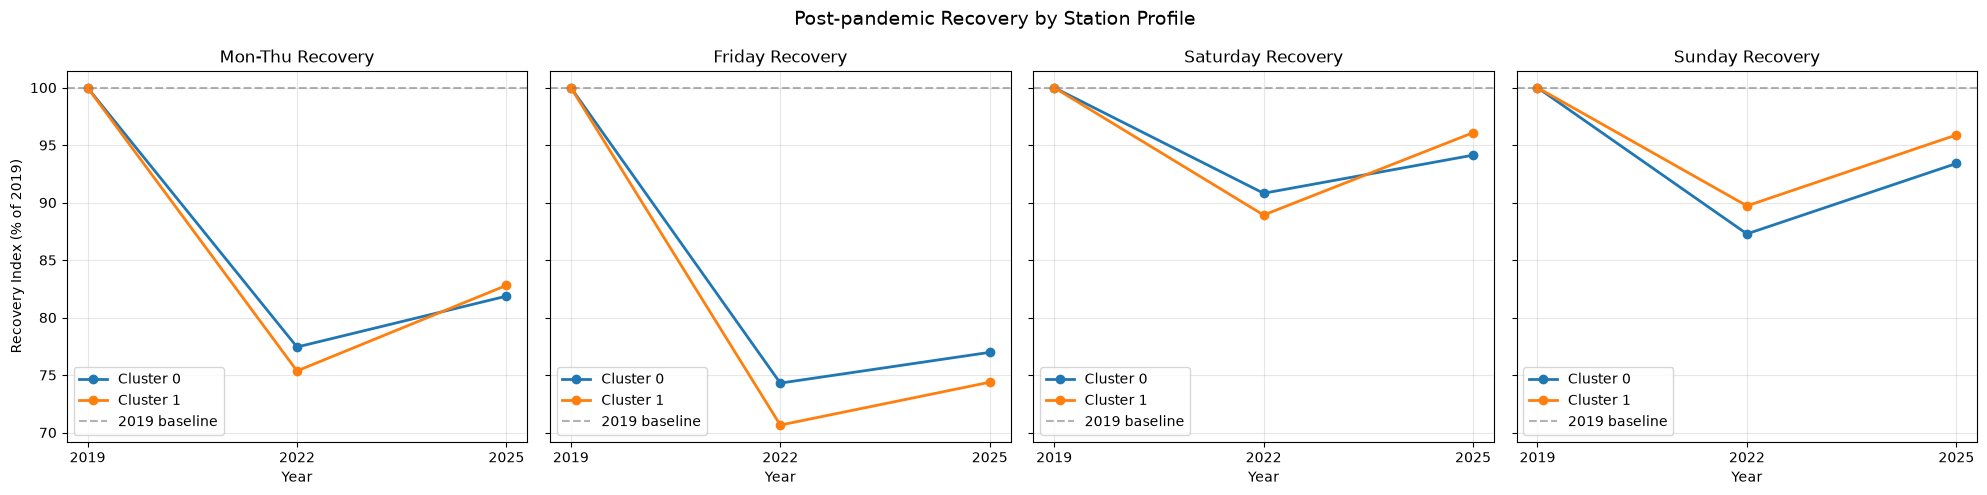

In [22]:
# ==========================================
# Cell 11: Visualise Recovery Patterns
# ==========================================

day_types = ["Mon-Thu", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
    sharey=True
)

for ax, day_type in zip(axes, day_types):

    subset = cluster_recovery[
        cluster_recovery["Day_Type"] == day_type
    ]

    for cluster in sorted(subset["Cluster"].unique()):

        cluster_data = subset[
            subset["Cluster"] == cluster
        ].sort_values("Year")

        ax.plot(
            cluster_data["Year"],
            cluster_data["Recovery_Index"],
            marker="o",
            linewidth=2,
            label=f"Cluster {cluster}"
        )

    ax.axhline(
        100,
        linestyle="--",
        color="grey",
        alpha=0.6,
        label="2019 baseline"
    )

    ax.set_title(f"{day_type} Recovery")
    ax.set_xlabel("Year")
    ax.set_xticks([2019, 2022, 2025])
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Recovery Index (% of 2019)")

plt.suptitle(
    "Post-pandemic Recovery by Station Profile",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# Cell 12: Export Recovery Results
# ==========================================

OUTPUT_DIR = PROJECT_DIR / "output" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cluster_recovery.to_csv(
    OUTPUT_DIR / "cluster_level_recovery.csv",
    index=False
)

recovery_pivot.to_csv(
    OUTPUT_DIR / "cluster_recovery_comparison.csv"
)

recovery_gap.to_csv(
    OUTPUT_DIR / "cluster_recovery_gap.csv",
    index=False
)

print("Recovery analysis complete.")
print("Files saved to:", OUTPUT_DIR)

print("\nCluster recovery preview:")
print(cluster_recovery.head(12))

print("\nRecovery gap:")
print(recovery_gap)

Recovery analysis complete.
Files saved to: /Users/ovo/Desktop/Grad/Internship/Data_for_Humanity_Internship/do-starter-playground/Model/output/tables

Cluster recovery preview:
    Year  Cluster Day_Type  Passenger_Flow  Baseline_2019  Recovery_Index
0   2019        0   Friday    2.922244e+06      2922244.0      100.000000
1   2022        0   Friday    2.171251e+06      2922244.0       74.300807
2   2025        0   Friday    2.249446e+06      2922244.0       76.976675
3   2019        1   Friday    6.680807e+06      6680807.0      100.000000
4   2022        1   Friday    4.720016e+06      6680807.0       70.650388
5   2025        1   Friday    4.969069e+06      6680807.0       74.378270
6   2019        0  Mon-Thu    2.892053e+06      2892053.0      100.000000
7   2022        0  Mon-Thu    2.239591e+06      2892053.0       77.439497
8   2025        0  Mon-Thu    2.367610e+06      2892053.0       81.866081
9   2019        1  Mon-Thu    6.458939e+06      6458939.0      100.000000
10  2022 